# Shorted noise-floor recording — 19:27:08, 2 November 2026

This notebook applies the same seven-figure spectral and CCA pipeline to the
independent 19:27:08 recording. The source is **raw ADC counts**, converted to
microvolts using metadata `uv_per_count`; no offline filter is added. The inputs
were shorted for the noise-floor run. There are no game logs, trial boundaries
or condition labels. The 17/19 Hz lines are inherited analysis targets and do
not imply that visual stimulation occurred during this recording.

One eight-channel inspection grid, two channel-mean spectra, and four CCA
projection spectra are exported as PNG/SVG with numeric spectra and audits.
The complete session is divided into 5-second epochs, DPSS NW=1/K=1, with a
0.2 Hz FFT grid. The last partial epoch is retained and padded with NaNs at
its end. Whole-session CCA uses one fit per target; rolling CCA uses a 1-second
window on an offline 100 ms schedule because this raw recording has no logged
CCA feature stream. No artifact rejection, CAR, filtering, interpolation, or
phase alignment is applied. Only C9–C16 were recorded; chip 3 is unavailable.


In [1]:
from pathlib import Path
from functools import lru_cache
import base64, hashlib, html, json, re
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy import signal
from IPython.display import HTML, display
ROOT = Path.cwd()
if not (ROOT / 'data/2026-11-02').is_dir():
    ROOT = Path(r'C:\Users\Kalyanbrata\Documents\Android\Analysis')
DATA_ROOT = ROOT / 'data/2026-11-02'
SESSION_IDS = ['eeg_20261102_192708']
SESSION_LABELS = {'eeg_20261102_192708': '250sps raw shorted noise floor'}
SESSION_FOLDERS = {'eeg_20261102_192708': 'eeg_20261102_192708_shorted-noisefloor'}
assert set(SESSION_IDS) == set(SESSION_LABELS) == set(SESSION_FOLDERS)
FS, TARGETS_HZ = 250.0, (17.0, 19.0)
EPOCH_SECONDS = 5.0
EPOCH_SAMPLES = int(round(FS * EPOCH_SECONDS))
WINDOW_SAMPLES, HOP_SAMPLES = 250, 25
RECORDED_CHANNEL_NAMES = [f'C{i}' for i in range(9, 17)]
RECORDED_CHANNEL_COLUMNS = [f'ch{i}_uv' for i in range(9, 17)]
CHANNEL_PSD_FREQ_LIMITS, FREQ_LIMITS = (5., 40.), (5., 30.)
PLOT_EXPORT_DPI = 200
EXPORT_ROOT = ROOT / 'plots' / f'2026-11-02_shorted_noisefloor_1927_{EPOCH_SECONDS:g}s'
EXPORT_ROOT.mkdir(parents=True, exist_ok=True)
plt.rcParams.update({'figure.dpi':110, 'axes.spines.top':False,
    'axes.spines.right':False, 'axes.grid':True, 'grid.alpha':.18, 'font.size':10})
assert EPOCH_SAMPLES >= 2

## Decode binary streams and audit coverage

Local `CogLab-Games/Packages/org.iisc.bcicore.server/Runtime/Logging/CsvSessionLogger.cs`
and `BinToCsvConverter.cs` define **134-byte little-endian records**: `uint32 seq`,
32 float32 microvolts or 32 int32 ADC counts, then `uint16 marker`. The first `num_ch`
slots are packed active channels mapped through zero-based metadata `ch_map`; the rest
are logger padding. Features are 112 bytes: `uint8 is_cca`, reserved byte, `uint16 marker`,
`uint32 seq`, 26 float32 values. Only `is_cca == 1` rows define logged CCA endpoints.

Sample duration is `N/fs`; wall duration includes acquisition/logging overhead. Counts,
sequence continuity, montage, finite values, padding and markers are checked before fitting.
Input SHA-256 hashes are exported for reproducibility.

In [2]:
SIGNAL_DTYPE = np.dtype([('seq','<u4'), ('values','<f4',(32,)), ('marker','<u2')])
RAW_DTYPE = np.dtype([('seq','<u4'), ('values','<i4',(32,)), ('marker','<u2')])
FEATURE_DTYPE = np.dtype([('is_cca','u1'), ('reserved','u1'), ('marker','<u2'),
    ('seq','<u4'), ('values','<f4',(26,))])
assert SIGNAL_DTYPE.itemsize == RAW_DTYPE.itemsize == 134
assert FEATURE_DTYPE.itemsize == 112

def read_records(path, dtype):
    if path.stat().st_size % dtype.itemsize:
        raise ValueError(f'{path.name}: incomplete binary record')
    return np.fromfile(path, dtype=dtype)

records, recording_rows, input_hashes = [], [], []
for session_id in SESSION_IDS:
    folder = DATA_ROOT / SESSION_FOLDERS[session_id]
    meta = json.loads((folder / f'{session_id}_meta.json').read_text(encoding='utf-8-sig'))
    if meta['fs'] != FS or meta['num_ch'] != 8 or meta['ch_map'] != list(range(8,16)):
        raise ValueError(f'{session_id}: unsupported sample rate/montage')
    raw = read_records(folder / f'{session_id}_raw.bin', RAW_DTYPE)
    filtered = read_records(folder / f'{session_id}_signals.bin', SIGNAL_DTYPE)
    features = read_records(folder / f'{session_id}_features.bin', FEATURE_DTYPE)
    assert len(raw)==meta['raw_samples'] and len(filtered)==meta['signals_samples']
    assert len(features)==meta['features_samples']
    if len(raw) and len(filtered):
        raise ValueError('Choose the source explicitly for a dual-stream session')
    if len(filtered):
        samples, source = filtered, 'board-filtered'
        x = samples['values'][:,:meta['num_ch']].astype(float)
    elif len(raw):
        samples, source = raw, 'raw, unfiltered'
        assert np.max(np.abs(raw['values'].astype(np.int64))) <= 2**23
        x = samples['values'][:,:meta['num_ch']].astype(float) * meta['uv_per_count']
    else:
        raise ValueError('No observed EEG')
    seq = samples['seq'].astype(np.int64)
    if len(seq)<WINDOW_SAMPLES or np.any(np.diff(seq)!=1) or not np.isfinite(x).all():
        raise ValueError(f'{session_id}: incomplete/nonfinite EEG; no interpolation performed')
    assert not np.any(samples['values'][:,meta['num_ch']:])
    assert not np.any(samples['marker']), 'Unexpected markers; review continuous grouping'
    assert np.isin(features['is_cca'],[0,1]).all() and not np.any(features['reserved'])
    cca_seq = features['seq'][features['is_cca']==1].astype(np.int64)
    assert not len(cca_seq) or np.all(np.diff(cca_seq)>=0)
    nfseq = np.unique(cca_seq)
    for path in sorted(folder.iterdir()):
        if path.is_file():
            input_hashes.append(dict(session=session_id, file=path.name, bytes=path.stat().st_size,
                sha256=hashlib.sha256(path.read_bytes()).hexdigest()))
    records.append(dict(session=session_id, label=SESSION_LABELS[session_id], meta=meta, seq=seq, markers=samples['marker'],
        recorded_x=x, nfseq=nfseq, source=source))
    recording_rows.append(dict(session=session_id, label=SESSION_LABELS[session_id], start_time=meta['start_time'], source=source,
        channels=x.shape[1], sample_rate_hz=FS, samples=len(seq), observed_seconds=len(seq)/FS,
        wall_duration_seconds=meta['duration_sec'], first_seq=int(seq[0]), last_seq=int(seq[-1]),
        signal_gap_events=int(np.count_nonzero(np.diff(seq)!=1)), nonfinite_values=int((~np.isfinite(x)).sum()),
        nonzero_markers=int(np.count_nonzero(samples['marker'])), raw_samples=len(raw),
        filtered_samples=len(filtered), feature_rows=len(features), logged_cca_updates=len(nfseq),
        duplicate_cca_rows=len(cca_seq)-len(nfseq),
        median_cca_hop_seconds=float(np.median(np.diff(nfseq))/FS) if len(nfseq)>1 else np.nan))
recording_audit = pd.DataFrame(recording_rows)
recording_audit.to_csv(EXPORT_ROOT / 'recording_audit.csv', index=False)
pd.DataFrame(input_hashes).to_csv(EXPORT_ROOT / 'input_sha256.csv', index=False)
display(recording_audit)

,session,label,start_time,source,channels,sample_rate_hz,samples,observed_seconds,wall_duration_seconds,first_seq,last_seq,signal_gap_events,nonfinite_values,nonzero_markers,raw_samples,filtered_samples,feature_rows,logged_cca_updates,duplicate_cca_rows,median_cca_hop_seconds
0,eeg_20261102_192708,250sps raw shorted noise floor,2026-11-02 19:27:08,"raw, unfiltered",8,250.0,150029,600.116,601.028,12830,162858,0,0,0,150029,0,0,0,0,NaN


## Spectral estimator from the reference notebook

Epoch the complete session with NaN tails; PSD calculations use observed samples only.
A partial epoch has equal weight but lower true resolution despite the shared FFT grid.
Waveform-first averaging uses only observed epochs at each sample position.

In [3]:
"""NaN-aware spectra for the configured epoch duration."""
import numpy as np
from scipy import signal

def epoch_trials(waveforms, epoch_samples):
    """Trial x epoch x sample [x projection]; retain every observed sample."""
    waves = [np.asarray(w, float) for w in waveforms]
    if not waves or epoch_samples < 2 or any(not np.isfinite(w).all() for w in waves):
        raise ValueError('Need nonempty, finite observed trials and a valid epoch length')
    tail_shape = waves[0].shape[1:]
    if any(w.shape[1:] != tail_shape for w in waves):
        raise ValueError('Projection shapes differ between trials')
    count = max((len(w)+epoch_samples-1)//epoch_samples for w in waves)
    result = np.full((len(waves), count, epoch_samples, *tail_shape), np.nan)
    for j, wave in enumerate(waves):
        for k, start in enumerate(range(0, len(wave), epoch_samples)):
            block = wave[start:start+epoch_samples]
            result[j, k, :len(block)] = block
    return result

def nan_epoch_psd(epoch, fs, epoch_samples):
    """Missing tails never enter detrending/tapering; common configured-length FFT grid."""
    x = np.asarray(epoch, float)
    valid = np.isfinite(x if x.ndim == 1 else x[:, 0])
    length = int(valid.sum())
    if not np.array_equal(valid, np.arange(len(x)) < length):
        raise ValueError('Only trailing NaNs are supported')
    f = np.fft.rfftfreq(epoch_samples, d=1/fs)
    if length < 2:
        return f, np.full((len(f), *x.shape[1:]), np.nan)
    observed = x[:length]
    if not np.isfinite(observed).all():
        raise ValueError('Inconsistent missing data across projections')
    # A 2-sample final fragment cannot support NW=1; use the largest legal NW.
    taper = signal.windows.dpss(length, NW=min(1., (length-1)/2), Kmax=1, sym=False)[0]
    return signal.periodogram(observed, fs=fs, window=taper, nfft=epoch_samples,
                              detrend='constant', scaling='density', axis=0)

def finite_mean(values, axis=0):
    values = np.asarray(values, float)
    count = np.isfinite(values).sum(axis=axis)
    total = np.nansum(values, axis=axis)
    return np.divide(total, count, out=np.full_like(total, np.nan), where=count > 0)

def pooled_trial_spectrum_orders(padded, fs):
    """Two epoch orders, with equal trial weighting in both operations."""
    n = padded.shape[2]
    epoch_power = np.stack([np.stack([nan_epoch_psd(e, fs, n)[1] for e in trial]) for trial in padded])
    # First average a trial's observed epoch spectra; then average trials equally.
    trial_power = finite_mean(epoch_power, axis=1)
    power_first = finite_mean(trial_power, axis=0)
    # First form each trial's NaN-aware mean epoch; then average those trials.
    trial_mean_epochs = finite_mean(padded, axis=1)
    mean_epoch = finite_mean(trial_mean_epochs, axis=0)
    f, waveform_first = nan_epoch_psd(mean_epoch, fs, n)
    counts = np.isfinite(trial_mean_epochs[..., 0] if trial_mean_epochs.ndim == 3 else trial_mean_epochs).sum(axis=0)
    return dict(f=f, induced=power_first, evoked=waveform_first, mean_epoch=mean_epoch,
                counts=counts, trial_power=trial_power, epoch_power=epoch_power)

## Inspect all eight channels separately

One 2 x 4 grid per session, 5-40 Hz. Dotted 17/19 Hz lines are inherited analysis targets.
Flat channels are labelled without an artificial dB floor. Full 0-125 Hz numeric spectra
and channel variability diagnostics are exported.


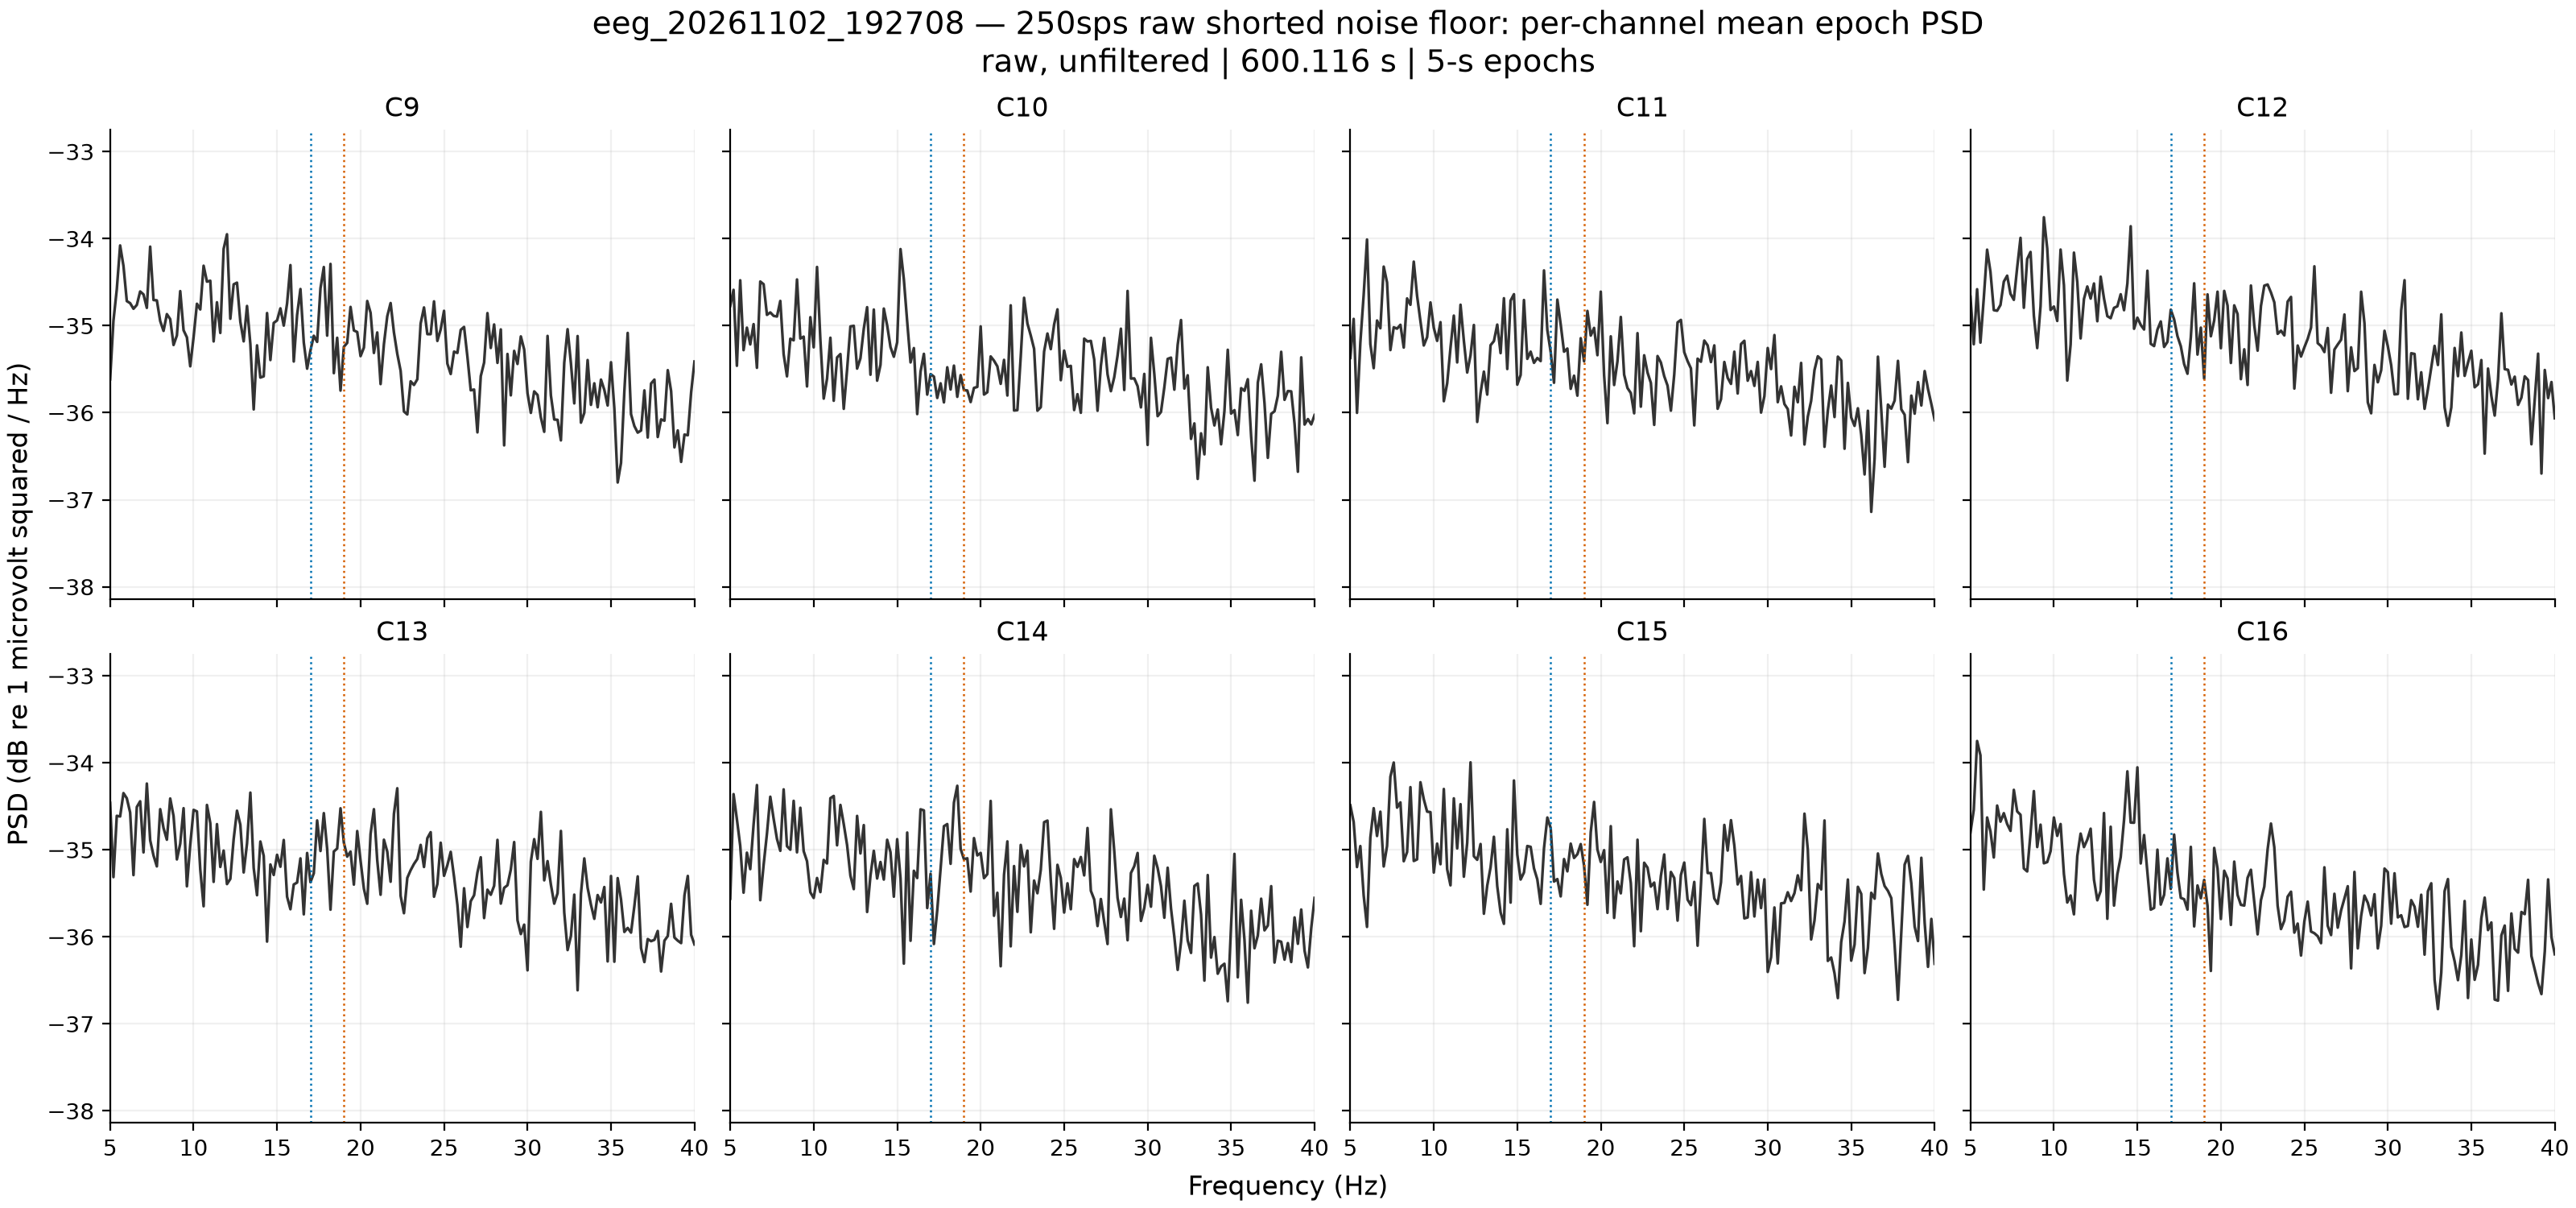

In [4]:
def db_plot(power):
    power = np.asarray(power, float)
    return 10*np.log10(np.where(power>0, power, np.nan))
def limits_for(powers):
    values = np.concatenate([db_plot(p).ravel() for p in powers])
    values = values[np.isfinite(values)]
    if not len(values): return (-1,1)
    lo, hi = values.min(), values.max()
    pad = max((hi-lo)*.05,1.)
    return lo-pad, hi+pad

plot_exports = []
def save_figure(fig, rec, stem, title, caption, view, method, order, folder):
    folder.mkdir(parents=True, exist_ok=True)
    png, svg = folder / f'{stem}.png', folder / f'{stem}.svg'
    fig.savefig(png, dpi=PLOT_EXPORT_DPI)
    fig.savefig(svg)
    plt.close(fig)
    plot_exports.append(dict(session=rec['session'], label=rec['label'], source=rec['source'], view=view,
        method=method, order=order, title=title, caption=caption,
        selected_channels=', '.join(CHANNEL_NAMES) if view!='per_channel' else ', '.join(RECORDED_CHANNEL_NAMES),
        png=png.relative_to(EXPORT_ROOT).as_posix(), svg=svg.relative_to(EXPORT_ROOT).as_posix()))
    encoded = base64.b64encode(png.read_bytes()).decode('ascii')
    return (f'<img src="data:image/png;base64,{encoded}" style="width:100%;height:auto" alt="{html.escape(title)}">'
        f'<p>{html.escape(caption)}</p><a href="{png.relative_to(ROOT).as_posix()}">PNG</a> | '
        f'<a href="{svg.relative_to(ROOT).as_posix()}">SVG</a>')

variability_rows, per_channel_numeric = [], []
for rec in records:
    x = rec['recorded_x']
    rec['channel_summary'] = pooled_trial_spectrum_orders(epoch_trials([x],EPOCH_SAMPLES), FS)
    summary = rec['channel_summary']
    f, power = summary['f'], summary['induced']
    mask = (f>=CHANNEL_PSD_FREQ_LIMITS[0]) & (f<=CHANNEL_PSD_FREQ_LIMITS[1])
    fig, axes = plt.subplots(2,4,figsize=(16,7.5),sharex=True,sharey=True,constrained_layout=True)
    ylim = limits_for([power[mask]])
    for j,(channel,ax) in enumerate(zip(RECORDED_CHANNEL_NAMES,axes.flat)):
        flat = bool(np.ptp(x[:,j])==0)
        variability_rows.append(dict(session=rec['session'], source=rec['source'], channel=channel,
            samples=len(x), std_uv=float(np.std(x[:,j])), peak_to_peak_uv=float(np.ptp(x[:,j])), flat=flat))
        ax.plot(f[mask],db_plot(power[mask,j]),color='#333333',lw=1.2)
        for hz,color in zip(TARGETS_HZ,('#0072B2','#D55E00')):
            ax.axvline(hz,color=color,ls=':',lw=.9)
        if flat: ax.text(.5,.5,'No measurable variance',transform=ax.transAxes,ha='center')
        ax.set(title=channel,xlim=CHANNEL_PSD_FREQ_LIMITS,ylim=ylim)
        per_channel_numeric.append(pd.DataFrame(dict(session=rec['session'],source=rec['source'],
            channel=channel,frequency_hz=f,power_uv2_per_hz=power[:,j])))
    title = f'{rec["session"]} — {rec["label"]}: per-channel mean epoch PSD'
    fig.suptitle(f'{title}\n{rec["source"]} | {len(x)/FS:.3f} s | {EPOCH_SECONDS:g}-s epochs',fontsize=14)
    fig.supxlabel('Frequency (Hz)')
    fig.supylabel('PSD (dB re 1 microvolt squared / Hz)')
    caption = (f'{rec["source"]}. All samples retained. {len(x)//EPOCH_SAMPLES} complete + '
        f'{int(bool(len(x)%EPOCH_SAMPLES))} partial epochs. Mean epoch PSD in linear power, each channel separately. '
        f'DPSS NW=1/K=1; {FS/EPOCH_SAMPLES:g} Hz FFT grid. Dotted blue/orange: 17/19 Hz analysis targets.')
    panel = save_figure(fig,rec,'per_channel_mean_epoch_psd',title,caption,'per_channel',
        'independent_channels','spectrum_first',EXPORT_ROOT / rec['session'])
    display(HTML(f'<h3>{html.escape(rec["session"])} — {html.escape(rec["label"])}</h3>{panel}'))
pd.DataFrame(variability_rows).to_csv(EXPORT_ROOT / 'per_channel_variability_audit.csv',index=False)
pd.concat(per_channel_numeric,ignore_index=True).to_csv(EXPORT_ROOT / 'per_channel_average_spectra.csv',index=False)

## Select channels for means and CCA

Edit the list and rerun this cell and everything below it. Inspection grids retain all channels.
Each selection has a separate results subfolder per session. C16 anchors CCA polarity when
selected; otherwise the largest absolute coefficient anchors polarity, as in the reference.

In [5]:
SELECTED_CHANNELS = ['C9','C10','C11','C12','C13','C14','C15','C16']
if (not isinstance(SELECTED_CHANNELS,(list,tuple)) or not SELECTED_CHANNELS or
        not all(isinstance(c,str) and c in RECORDED_CHANNEL_NAMES for c in SELECTED_CHANNELS) or
        len(set(SELECTED_CHANNELS))!=len(SELECTED_CHANNELS)):
    raise ValueError('Use a nonempty list of unique channel names from C9-C16')
CHANNEL_NAMES = list(SELECTED_CHANNELS)
SELECTED_CHANNEL_INDICES = [RECORDED_CHANNEL_NAMES.index(c) for c in CHANNEL_NAMES]
CHANNEL_COLUMNS = [RECORDED_CHANNEL_COLUMNS[i] for i in SELECTED_CHANNEL_INDICES]
SIGN_ANCHOR_INDEX = CHANNEL_NAMES.index('C16') if 'C16' in CHANNEL_NAMES else None
CHANNEL_LIST_TEXT = ', '.join(CHANNEL_NAMES)
SELECTION_TAG = 'channels_' + '_'.join(c[1:] for c in CHANNEL_NAMES)
for rec in records:
    rec['x'] = np.ascontiguousarray(rec['recorded_x'][:,SELECTED_CHANNEL_INDICES])
    rec['export_dir'] = EXPORT_ROOT / rec['session'] / SELECTION_TAG
    rec['export_dir'].mkdir(parents=True,exist_ok=True)
    selection = dict(session=rec['session'],label=rec['label'],selected_channels=CHANNEL_NAMES,
        recorded_channels=RECORDED_CHANNEL_NAMES,sample_rate_hz=FS,epoch_seconds=EPOCH_SECONDS,
        source=rec['source'],raw_preprocessing='raw ADC counts * metadata uv_per_count; no offline filter',
        polarity_anchor='C16' if SIGN_ANCHOR_INDEX is not None else 'largest absolute coefficient')
    (rec['export_dir'] / 'selected_channels.json').write_text(json.dumps(selection,indent=2),encoding='utf-8')
plot_exports = [p for p in plot_exports if p['view']=='per_channel']
print('Downstream channels:',CHANNEL_LIST_TEXT)

Downstream channels: C9, C10, C11, C12, C13, C14, C15, C16


## Independent 17 Hz and 19 Hz CCA projections

The following CCA implementation and recovery/rank checks come from the reference notebook.
Direct data SVD avoids squaring the condition number. Each target has exactly two sine/cosine
columns and independent unit-norm EEG weights. Rolling fits use complete 1-second windows;
only newly covered samples are assigned. Fit means, weights, bounds, correlations and
endpoint provenance are saved. The raw session remains unfiltered for both CCA methods.

In [6]:
def reference_matrix(time_seconds, frequencies_hz):
    t = np.asarray(time_seconds, dtype=float)
    return np.column_stack([func(2*np.pi*f*t)
                            for f in frequencies_hz for func in (np.sin, np.cos)])

def joint_reference(time_seconds):
    return reference_matrix(time_seconds, TARGETS_HZ)

def whitening_basis(centered):
    # Direct data SVD avoids squaring the condition number through X.T @ X.
    q, singular_values, rotation = np.linalg.svd(centered, full_matrices=False)
    tolerance = max(centered.shape) * np.finfo(float).eps * singular_values[0]
    keep = singular_values > tolerance
    if not np.any(keep):
        raise ValueError('No nonzero variance for CCA')
    return rotation[keep].T / singular_values[keep], q[:, keep]

def fit_cca_projection(eeg_uv, time_seconds, frequencies_hz):
    x, y = np.asarray(eeg_uv, float), reference_matrix(time_seconds, frequencies_hz)
    if x.ndim != 2 or x.shape[0] != y.shape[0] or x.shape[1] != len(CHANNEL_COLUMNS):
        raise ValueError('Expected samples x selected channels and matching reference times')
    if len(x) <= x.shape[1]+y.shape[1] or not np.isfinite(x).all():
        raise ValueError('Insufficient samples or non-finite EEG')
    x_mean, y_mean = x.mean(axis=0), y.mean(axis=0)
    xc, yc = x-x_mean, y-y_mean
    (bx, qx), (by, qy) = whitening_basis(xc), whitening_basis(yc)
    left, strengths, right = np.linalg.svd(qx.T @ qy, full_matrices=False)
    w, v = bx @ left[:, 0], by @ right[0]
    w /= np.linalg.norm(w)
    v /= np.linalg.norm(v)
    anchor = SIGN_ANCHOR_INDEX
    fallback = anchor is None or abs(w[anchor]) <= 1e-12
    if fallback:
        anchor = int(np.argmax(np.abs(w)))
    if w[anchor] < 0:
        w, v = -w, -v
    u = xc @ w
    rho = float(np.corrcoef(u, yc @ v)[0, 1])
    if not np.isfinite(rho):
        raise ValueError('Degenerate projected variance')
    return dict(w=w, v=v, x_mean=x_mean, y_mean=y_mean, u=u, rho=rho,
                rho_svd=float(np.clip(strengths[0], 0, 1)), x_rank=bx.shape[1],
                y_rank=by.shape[1], sign_fallback=fallback,
                frequencies_hz=tuple(frequencies_hz), reference_columns=y.shape[1])

def fit_joint_cca(eeg_uv, time_seconds):
    return fit_cca_projection(eeg_uv, time_seconds, TARGETS_HZ)

def fit_target_cca(eeg_uv, time_seconds, target_hz):
    # Exactly two reference columns; each call estimates its own EEG weights.
    return fit_cca_projection(eeg_uv, time_seconds, (float(target_hz),))

@lru_cache(maxsize=None)
def dpss_taper(n_samples):
    return signal.windows.dpss(n_samples, NW=1, Kmax=1, sym=False)[0]

def psd(data, nfft=None):
    x = np.asarray(data, float)
    return signal.periodogram(x, fs=FS, window=dpss_taper(len(x)), nfft=len(x) if nfft is None else nfft,
        detrend='constant', return_onesided=True, scaling='density', axis=0)

def db(power):
    return 10*np.log10(np.maximum(np.asarray(power), np.finfo(float).tiny))

# Known linear mixture, rank deficiency, scaling, and phase-cancellation checks.
rng = np.random.default_rng(17)
t_test = np.arange(1000)/FS
r_test = joint_reference(t_test)
x_test = r_test @ rng.normal(size=(4, len(CHANNEL_COLUMNS)))
x_test += rng.normal(scale=.01, size=x_test.shape)
fit_test = fit_joint_cca(x_test, t_test)
assert fit_test['rho'] > .999
assert np.isclose(np.linalg.norm(fit_test['w']), 1)
assert np.isclose(fit_test['rho'], fit_test['rho_svd'], atol=1e-10)
assert fit_joint_cca(np.tile(r_test[:, :1], (1, len(CHANNEL_COLUMNS))), t_test)['x_rank'] == 1
assert len(psd(fit_test['u'])[0]) == 501
for target in TARGETS_HZ:
    # A target-specific mixture supports this check even with one selected channel.
    target_ref = reference_matrix(t_test, (target,))
    target_eeg = target_ref @ rng.normal(size=(2, len(CHANNEL_COLUMNS)))
    target_eeg += rng.normal(scale=.001, size=target_eeg.shape)
    single = fit_target_cca(target_eeg, t_test, target)
    assert single['reference_columns'] == 2 and single['rho'] > .999
if len(CHANNEL_COLUMNS) >= 2:
    # Independent spatial sources require at least two selected channels.
    x_two = np.zeros((1000, len(CHANNEL_COLUMNS)))
    x_two[:, 0], x_two[:, 1] = r_test[:, 0], r_test[:, 2]
    fit17 = fit_target_cca(x_two, t_test, 17)
    fit19 = fit_target_cca(x_two, t_test, 19)
    assert fit17['rho'] > .999999 and fit19['rho'] > .999999
    assert abs(np.corrcoef(fit17['u'], fit19['u'])[0, 1]) < 1e-10
sine = np.sin(2*np.pi*17*np.arange(500)/FS)
assert psd(np.mean([sine, -sine], axis=0))[1].max() == 0
assert np.mean([psd(sine)[1], psd(-sine)[1]], axis=0).max() > 0
print('CCA recovery, rank handling, scaling and averaging-order checks passed.')

CCA recovery, rank handling, scaling and averaging-order checks passed.


In [7]:
fixed_fit_rows,rolling_fit_rows,coverage_rows = [],[],[]
for rec in records:
    x,seq = rec['x'],rec['seq']
    n = len(x)
    times = (seq-seq[0])/FS
    rec['fixed_fits'] = [fit_target_cca(x,times,hz) for hz in TARGETS_HZ]
    rec['fixed_u'] = np.column_stack([fit['u'] for fit in rec['fixed_fits']])
    for hz,fit in zip(TARGETS_HZ,rec['fixed_fits']):
        row = dict(session=rec['session'],source=rec['source'],target_hz=hz,
            rho=fit['rho'],rho_svd=fit['rho_svd'],x_rank=fit['x_rank'],sign_fallback=fit['sign_fallback'],samples=n)
        row.update({f'weight_{c}':float(w) for c,w in zip(CHANNEL_NAMES,fit['w'])})
        row.update({f'mean_{c}_uv':float(v) for c,v in zip(CHANNEL_NAMES,fit['x_mean'])})
        fixed_fit_rows.append(row)
    endpoints = {}
    if len(rec['nfseq']):
        for endpoint_seq in rec['nfseq']:
            pos = int(np.searchsorted(seq,endpoint_seq))
            if WINDOW_SAMPLES-1<=pos<n and seq[pos]==endpoint_seq:
                endpoints[pos] = 'logged CCA endpoint'
        schedule = 'logged CCA endpoints + offline boundary endpoints'
    else:
        endpoints = {p:'offline 100 ms schedule' for p in range(WINDOW_SAMPLES-1,n,HOP_SAMPLES)}
        schedule = 'offline 100 ms schedule (no logged CCA stream)'
    endpoints.setdefault(WINDOW_SAMPLES-1,'offline first complete window')
    endpoints.setdefault(n-1,'offline final sample')
    projected = np.full((n,len(TARGETS_HZ)),np.nan)
    assigned = np.full(n,-1,dtype=np.int64)
    cursor = 0
    rec['update_fits'] = []
    for pos,endpoint_source in sorted(endpoints.items()):
        window_start,hi = pos-WINDOW_SAMPLES+1,pos+1
        if cursor<window_start:
            raise ValueError(f'{rec["session"]}: uncovered interval between rolling fits')
        fits = [fit_target_cca(x[window_start:hi],times[window_start:hi],hz) for hz in TARGETS_HZ]
        lo = cursor
        assert hi>lo
        projected[lo:hi] = np.column_stack([(x[lo:hi]-fit['x_mean']) @ fit['w'] for fit in fits])
        assigned[lo:hi] = int(seq[pos])
        rec['update_fits'].append(dict(pos=pos,lo=lo,hi=hi,fits=fits,source=endpoint_source))
        for hz,fit in zip(TARGETS_HZ,fits):
            row = dict(session=rec['session'],source=rec['source'],target_hz=hz,
                endpoint_source=endpoint_source,endpoint_seq=int(seq[pos]),endpoint_seconds=pos/FS,
                fit_start_seq=int(seq[window_start]),fit_samples=hi-window_start,
                assigned_first_seq=int(seq[lo]),assigned_last_seq=int(seq[hi-1]),assigned_samples=hi-lo,
                rho=fit['rho'],rho_svd=fit['rho_svd'],x_rank=fit['x_rank'],sign_fallback=fit['sign_fallback'])
            row.update({f'weight_{c}':float(w) for c,w in zip(CHANNEL_NAMES,fit['w'])})
            row.update({f'mean_{c}_uv':float(v) for c,v in zip(CHANNEL_NAMES,fit['x_mean'])})
            rolling_fit_rows.append(row)
        cursor = hi
    assert cursor==n and np.isfinite(projected).all()
    assert np.all(assigned>=seq) and np.all(assigned-seq<WINDOW_SAMPLES)
    rec['refitted_u'],rec['assigned'],rec['schedule'] = projected,assigned,schedule
    coverage_rows.append(dict(session=rec['session'],samples=n,fixed_projected_samples=len(rec['fixed_u']),
        rolling_projected_samples=len(projected),unassigned_samples=int(np.count_nonzero(assigned<0)),
        rolling_fit_count=len(endpoints),logged_fits_used=sum(s=='logged CCA endpoint' for s in endpoints.values()),
        offline_fits_used=sum(s!='logged CCA endpoint' for s in endpoints.values()),schedule=schedule))
    print(rec['session'],':',len(endpoints),'rolling fits;',schedule)
fixed_fit_audit,rolling_fit_audit = pd.DataFrame(fixed_fit_rows),pd.DataFrame(rolling_fit_rows)
coverage_audit = pd.DataFrame(coverage_rows)
for rec in records:
    for name,table in [('fixed_cca_weights',fixed_fit_audit),('rolling_cca_fit_audit',rolling_fit_audit),
                       ('projection_coverage_audit',coverage_audit)]:
        table.loc[table.session.eq(rec['session'])].to_csv(rec['export_dir'] / f'{name}.csv',index=False)
display(coverage_audit)

eeg_20261102_192708 : 5993 rolling fits; offline 100 ms schedule (no logged CCA stream)


,session,samples,fixed_projected_samples,rolling_projected_samples,unassigned_samples,rolling_fit_count,logged_fits_used,offline_fits_used,schedule
0,eeg_20261102_192708,150029,150029,150029,0,5993,0,5993,offline 100 ms schedule (no logged CCA stream)


## Epoch complete session waveforms and compare averaging orders

The same observed samples, epoch boundaries, DPSS estimator and FFT grid enter channel
means and both CCA methods. Everything is calculated independently within a session.
There is no cross-session averaging or alignment.

In [8]:
epoch_rows = []
for rec in records:
    n = len(rec['x'])
    for k,start in enumerate(range(0,n,EPOCH_SAMPLES)):
        observed = min(EPOCH_SAMPLES,n-start)
        epoch_rows.append(dict(session=rec['session'],epoch=k+1,start_seconds=start/FS,
            first_seq=int(rec['seq'][start]),last_seq=int(rec['seq'][start+observed-1]),
            observed_samples=observed,padded_samples=EPOCH_SAMPLES-observed,complete=observed==EPOCH_SAMPLES))
    rec['summaries'] = {}
    for method,wave in [('channel_mean',rec['x'].mean(axis=1)),
                         ('whole_session_cca',rec['fixed_u']),('rolling_cca',rec['refitted_u'])]:
        padded = epoch_trials([wave],EPOCH_SAMPLES)
        summary = pooled_trial_spectrum_orders(padded,FS)
        summary.update(padded=padded,waveform=wave,complete=n//EPOCH_SAMPLES,
            partial=int(bool(n%EPOCH_SAMPLES)),epochs=(n+EPOCH_SAMPLES-1)//EPOCH_SAMPLES)
        rec['summaries'][method] = summary
    numeric = []
    for method,summary in rec['summaries'].items():
        for order in ('induced','evoked'):
            power = summary[order]
            if power.ndim==1: power=power[:,None]
            for j in range(power.shape[1]):
                numeric.append(pd.DataFrame(dict(session=rec['session'],source=rec['source'],method=method,
                    order='spectrum_first' if order=='induced' else 'waveform_first',
                    component='channel_mean' if method=='channel_mean' else f'U{TARGETS_HZ[j]:g}',
                    frequency_hz=summary['f'],power_uv2_per_hz=power[:,j],selected_channels=CHANNEL_LIST_TEXT)))
    pd.concat(numeric,ignore_index=True).to_csv(rec['export_dir'] / 'spectra.csv',index=False)
epoch_audit = pd.DataFrame(epoch_rows)
for rec in records:
    epoch_audit.loc[epoch_audit.session.eq(rec['session'])].to_csv(rec['export_dir'] / 'epoch_audit.csv',index=False)
display(epoch_audit.groupby('session').agg(epochs=('epoch','count'),observed_samples=('observed_samples','sum'),
    complete_epochs=('complete','sum'),padded_samples=('padded_samples','sum')))

,epochs,observed_samples,complete_epochs,padded_samples
session,,,,
eeg_20261102_192708,121,150029,120,1221


In [9]:
METHOD_TITLES = {'channel_mean':'Arithmetic channel mean',
    'whole_session_cca':'Whole-session CCA','rolling_cca':'Rolling 1-s CCA'}
ORDER_TITLES = {'induced':'Mean of epoch PSDs','evoked':'PSD of mean epoch waveform'}

def plot_session(rec):
    plot_exports[:] = [p for p in plot_exports if p['session']!=rec['session'] or p['view']=='per_channel']
    rows = []
    for order in ('induced','evoked'):
        panels = []
        f = rec['summaries']['channel_mean']['f']
        mask = (f>=FREQ_LIMITS[0]) & (f<=FREQ_LIMITS[1])
        cca_ylim = limits_for([rec['summaries'][m][order][mask] for m in ('whole_session_cca','rolling_cca')])
        for method,s in rec['summaries'].items():
            fig,ax = plt.subplots(figsize=(6.4,4.5),constrained_layout=True)
            power = s[order]
            if method=='channel_mean':
                ax.plot(f[mask],db_plot(power[mask]),color='#333333',lw=2,label='Channel mean')
                ylim = limits_for([power[mask]])
            else:
                for j,(hz,color) in enumerate(zip(TARGETS_HZ,('#0072B2','#D55E00'))):
                    ax.plot(f[mask],db_plot(power[mask,j]),color=color,lw=2,label=f'U{hz:g}')
                ylim = cca_ylim
            for hz,color in zip(TARGETS_HZ,('#0072B2','#D55E00')):
                ax.axvline(hz,color=color,ls=':',lw=1)
            title = f'{rec["session"]} — {rec["label"]}\n{METHOD_TITLES[method]} | {ORDER_TITLES[order]}\n{rec["source"]}'
            ax.set(title=title,xlabel='Frequency (Hz)',ylabel='PSD (dB re 1 microvolt squared / Hz)',
                xlim=FREQ_LIMITS,ylim=ylim)
            ax.legend(fontsize=8)
            method_note = ('Mean of selected channels before epoching.' if method=='channel_mean' else
                'Independent target weights fitted once using the whole session.' if method=='whole_session_cca' else
                f'Latest 1-s windows; {rec["schedule"]}. First window back-projected; offline analysis.')
            averaging = ('PSD per epoch, then equal epoch mean in linear power.' if order=='induced' else
                'NaN-aware mean epoch waveform, then PSD. No event alignment.')
            caption = (f'{rec["source"]}; channels: {CHANNEL_LIST_TEXT}. {method_note} {averaging} '
                f'{s["complete"]} complete + {s["partial"]} partial {EPOCH_SECONDS:g}-s epochs; '
                f'{len(rec["x"])} samples, all retained. DPSS NW=1/K=1; {FS/EPOCH_SAMPLES:g} Hz FFT grid. '
                '17/19 Hz are inherited targets, not verified stimuli.')
            panels.append(save_figure(fig,rec,f'{method}_{order}',title,caption,
                'channel_mean' if method=='channel_mean' else 'cca',method,
                'spectrum_first' if order=='induced' else 'waveform_first',rec['export_dir']))
        rows.append('<tr>'+''.join(f'<td style="width:33.3%;vertical-align:top;padding:8px;border:1px solid #ccc">{p}</td>' for p in panels)+'</tr>')
    display(HTML(f'<h3>{html.escape(rec["session"])} — {html.escape(rec["label"])} — {html.escape(rec["source"])}</h3>'
        '<table style="width:100%;table-layout:fixed;border-collapse:collapse">'
        '<thead><tr><th>Channel mean</th><th>Whole-session CCA</th><th>Rolling CCA</th></tr></thead>'
        f'<tbody>{"".join(rows)}</tbody></table>'))

## 19:27:08 shorted noise-floor run

Top row: spectrum first. Bottom row: waveform first. The source is raw, unfiltered ADC counts scaled to microvolts.

Channel mean,Whole-session CCA,Rolling CCA
"raw, unfiltered; channels: C9, C10, C11, C12, C13, C14, C15, C16. Mean of selected channels before epoching. PSD per epoch, then equal epoch mean in linear power. 120 complete + 1 partial 5-s epochs; 150029 samples, all retained. DPSS NW=1/K=1; 0.2 Hz FFT grid. 17/19 Hz are inherited targets, not verified stimuli.PNG | SVG","raw, unfiltered; channels: C9, C10, C11, C12, C13, C14, C15, C16. Independent target weights fitted once using the whole session. PSD per epoch, then equal epoch mean in linear power. 120 complete + 1 partial 5-s epochs; 150029 samples, all retained. DPSS NW=1/K=1; 0.2 Hz FFT grid. 17/19 Hz are inherited targets, not verified stimuli.PNG | SVG","raw, unfiltered; channels: C9, C10, C11, C12, C13, C14, C15, C16. Latest 1-s windows; offline 100 ms schedule (no logged CCA stream). First window back-projected; offline analysis. PSD per epoch, then equal epoch mean in linear power. 120 complete + 1 partial 5-s epochs; 150029 samples, all retained. DPSS NW=1/K=1; 0.2 Hz FFT grid. 17/19 Hz are inherited targets, not verified stimuli.PNG | SVG"
"raw, unfiltered; channels: C9, C10, C11, C12, C13, C14, C15, C16. Mean of selected channels before epoching. NaN-aware mean epoch waveform, then PSD. No event alignment. 120 complete + 1 partial 5-s epochs; 150029 samples, all retained. DPSS NW=1/K=1; 0.2 Hz FFT grid. 17/19 Hz are inherited targets, not verified stimuli.PNG | SVG","raw, unfiltered; channels: C9, C10, C11, C12, C13, C14, C15, C16. Independent target weights fitted once using the whole session. NaN-aware mean epoch waveform, then PSD. No event alignment. 120 complete + 1 partial 5-s epochs; 150029 samples, all retained. DPSS NW=1/K=1; 0.2 Hz FFT grid. 17/19 Hz are inherited targets, not verified stimuli.PNG | SVG","raw, unfiltered; channels: C9, C10, C11, C12, C13, C14, C15, C16. Latest 1-s windows; offline 100 ms schedule (no logged CCA stream). First window back-projected; offline analysis. NaN-aware mean epoch waveform, then PSD. No event alignment. 120 complete + 1 partial 5-s epochs; 150029 samples, all retained. DPSS NW=1/K=1; 0.2 Hz FFT grid. 17/19 Hz are inherited targets, not verified stimuli.PNG | SVG"

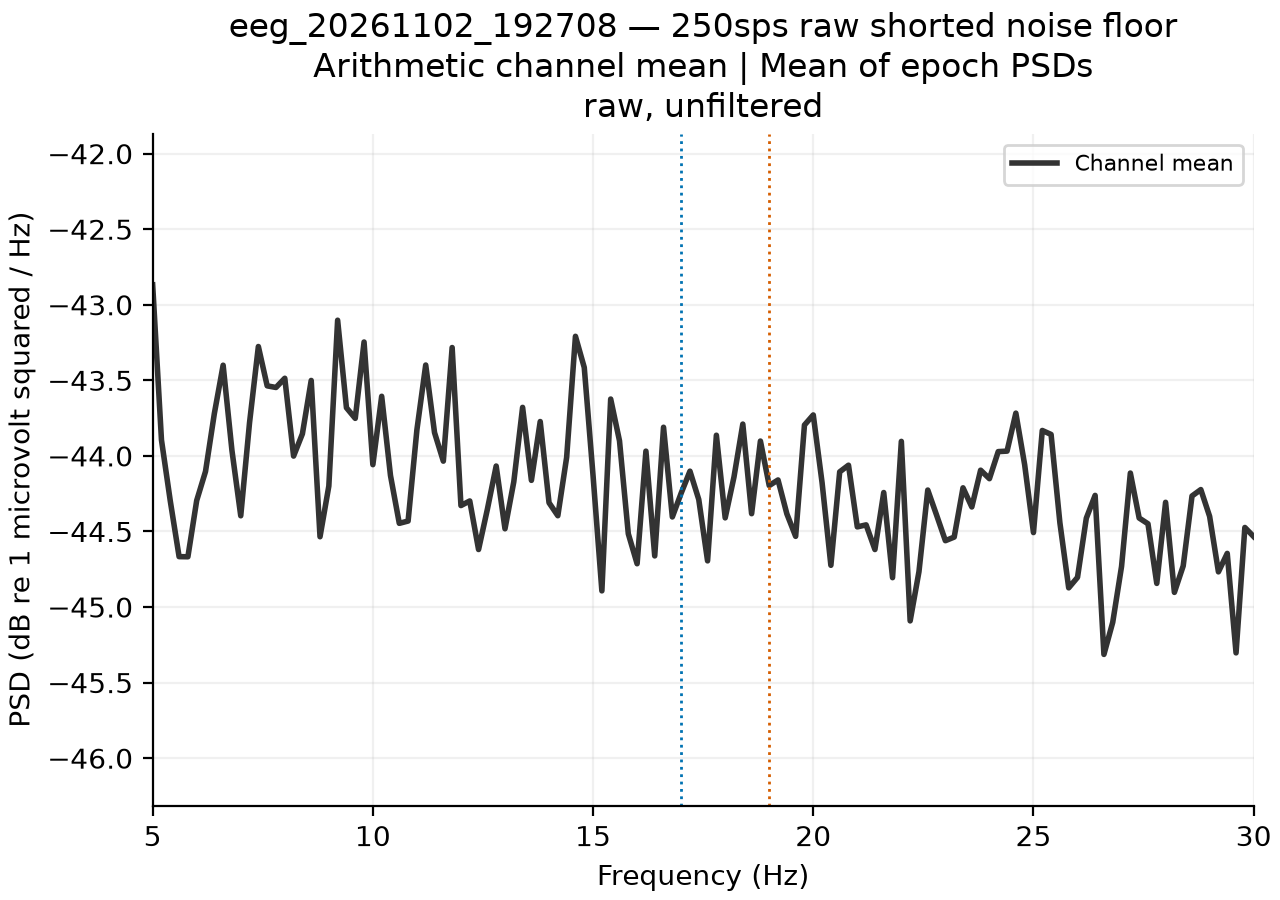
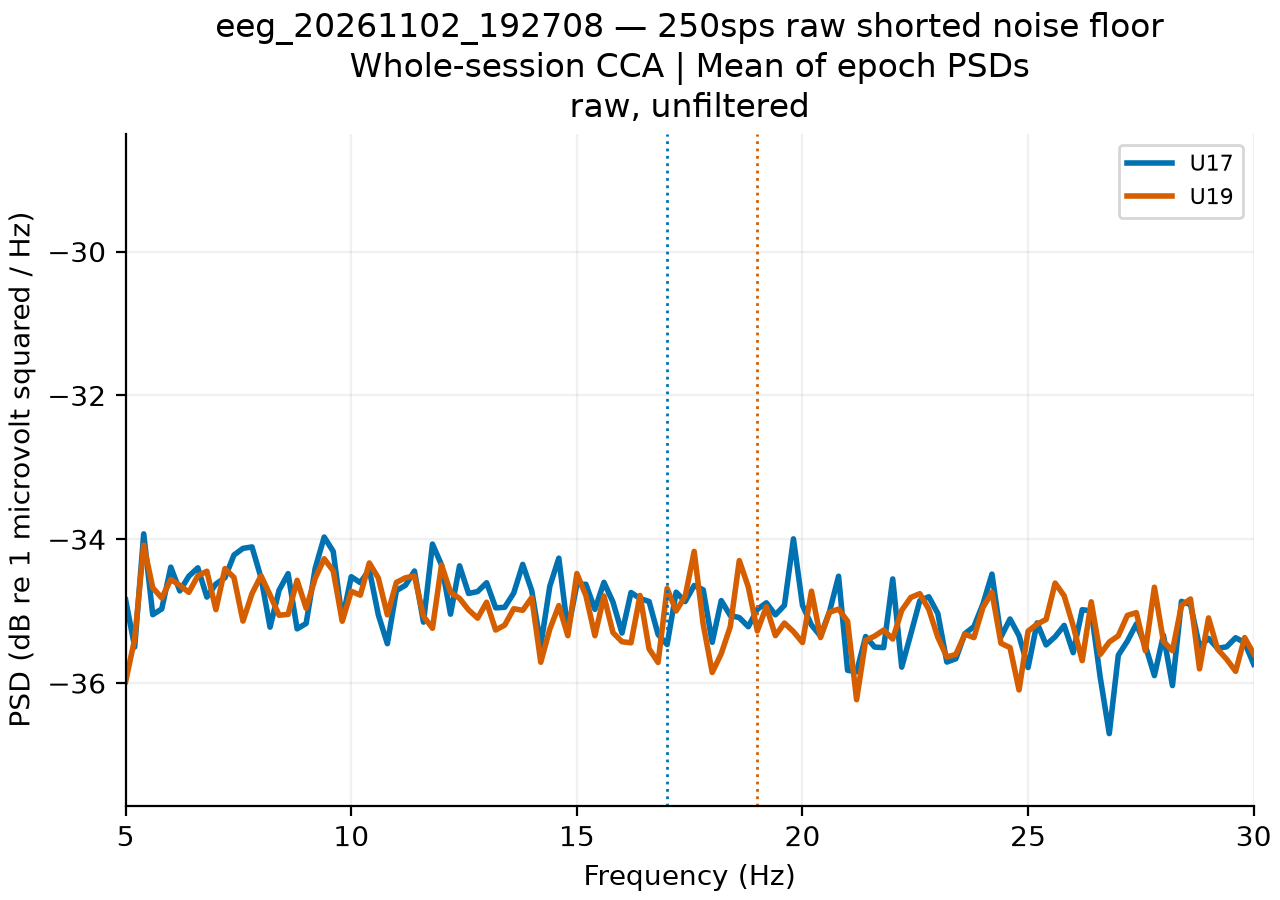
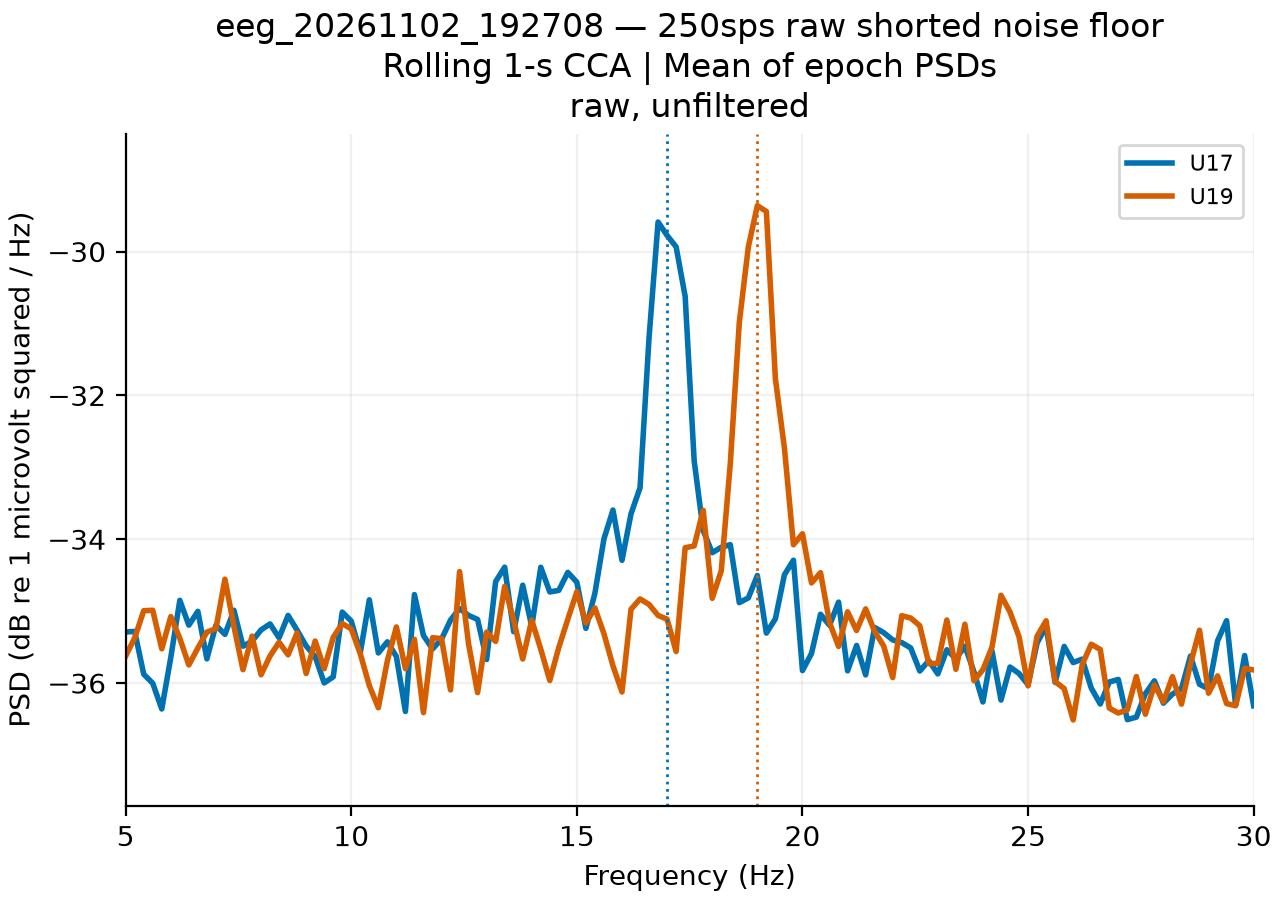
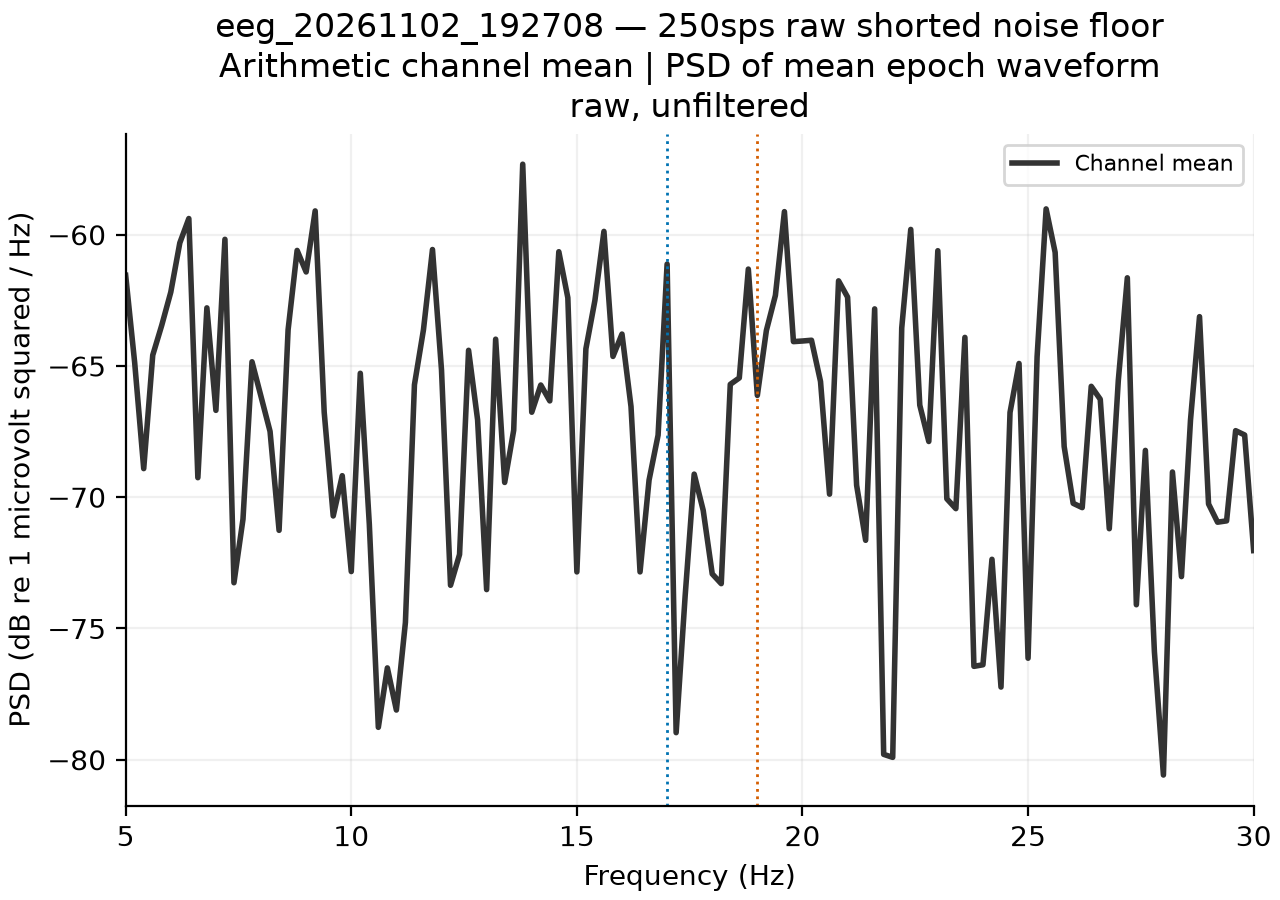
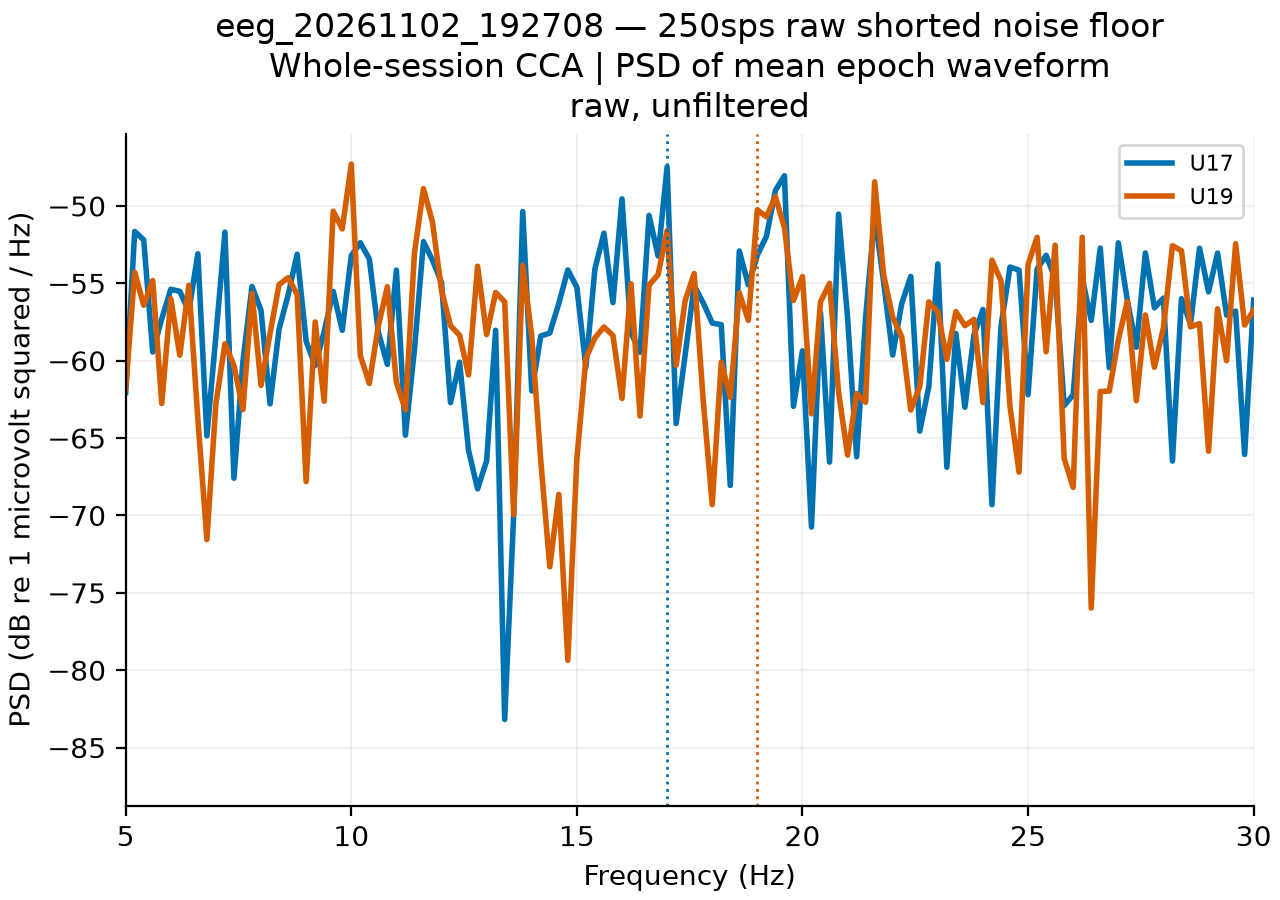
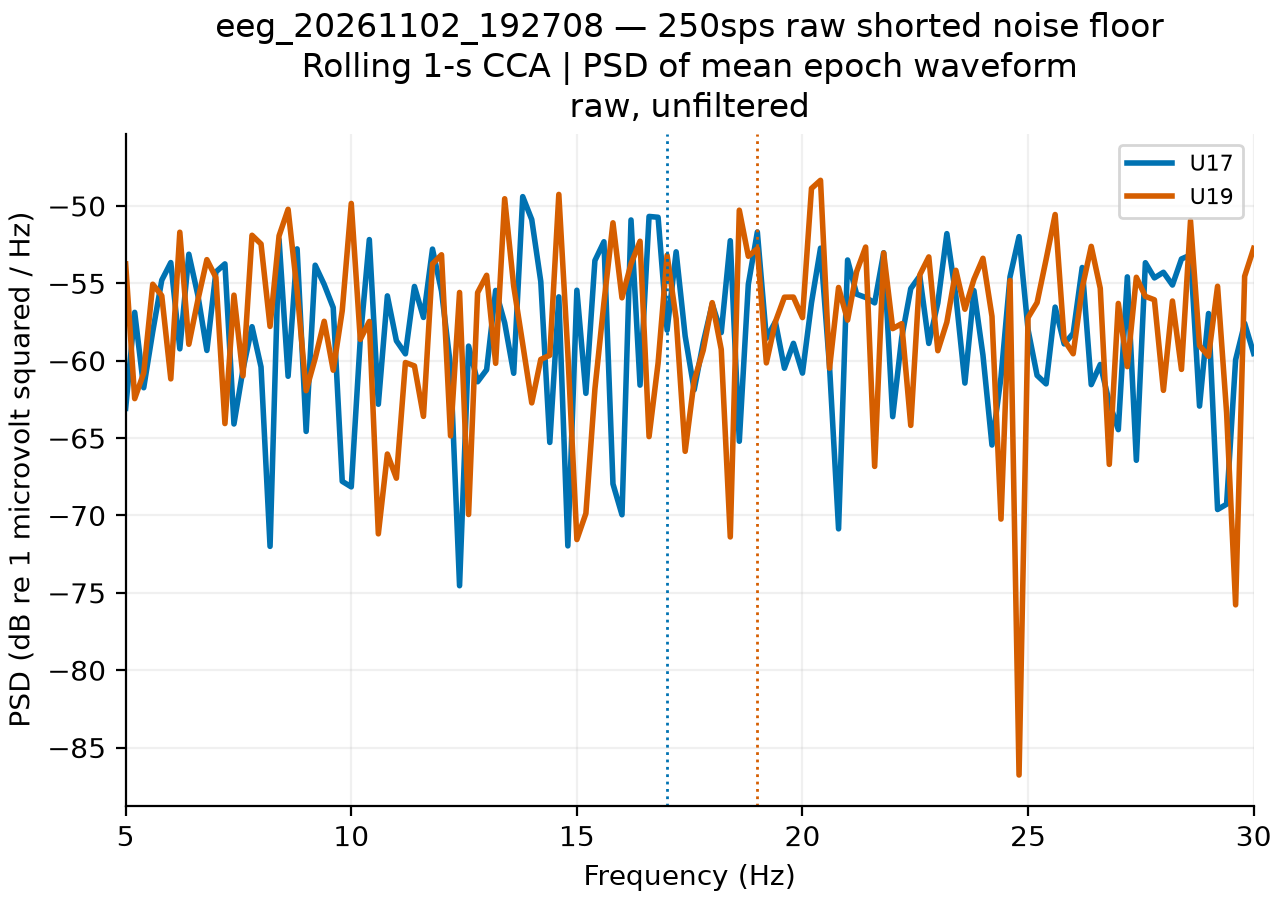

In [10]:
plot_session(records[0])

## Verify coverage, projections, spectra and exports

Checks cover byte order against Python's struct decoder, exact observed-sample preservation,
trailing NaNs, rolling assignment inside its fitted window, projection recovery from weights,
unit norms, matched epoch membership and all seven figures. The HTML report uses relative images
and can be opened directly from the results folder.

In [11]:
import struct
for rec in records:
    session = rec['session']
    kind = 'signals' if rec['source']=='board-filtered' else 'raw'
    path = DATA_ROOT / SESSION_FOLDERS[session] / f'{session}_{kind}.bin'
    first = struct.unpack('<I32fH' if kind=='signals' else '<I32iH',path.read_bytes()[:134])
    expected = np.array(first[1:9])*(1 if kind=='signals' else rec['meta']['uv_per_count'])
    assert first[0]==rec['seq'][0] and first[-1]==rec['markers'][0]
    assert np.array_equal(expected,rec['recorded_x'][0])
    assert np.array_equal(rec['x'],rec['recorded_x'][:,SELECTED_CHANNEL_INDICES])
    audit = epoch_audit.loc[epoch_audit.session.eq(session)]
    assert audit.observed_samples.sum()==len(rec['x'])
    assert coverage_audit.set_index('session').loc[session,'unassigned_samples']==0
    for s in rec['summaries'].values():
        wave = s['waveform']
        flat = s['padded'][0].reshape((-1,*wave.shape[1:]))
        assert np.array_equal(flat[:len(wave)],wave)
        assert np.isnan(flat[len(wave):]).all()
        assert np.allclose(s['induced'],finite_mean(s['epoch_power'][0],axis=0))
        assert np.allclose(s['evoked'],nan_epoch_psd(s['mean_epoch'],FS,EPOCH_SAMPLES)[1])
        assert np.isfinite(s['induced']).all() and np.isfinite(s['evoked']).all()
        assert np.isclose(np.diff(s['f']),FS/EPOCH_SAMPLES).all()
        assert s['epochs']==len(audit)
    assert np.array_equal(rec['summaries']['channel_mean']['waveform'],rec['x'].mean(axis=1))
    for hz,fit in zip(TARGETS_HZ,rec['fixed_fits']):
        assert fit['reference_columns']==2 and fit['frequencies_hz']==(hz,)
        assert np.isclose(np.linalg.norm(fit['w']),1)
        assert np.isclose(fit['rho'],fit['rho_svd'],atol=1e-9)
    for update in rec['update_fits']:
        a,b = update['lo'],update['hi']
        reconstructed = np.column_stack([(rec['x'][a:b]-fit['x_mean']) @ fit['w'] for fit in update['fits']])
        assert np.allclose(rec['refitted_u'][a:b],reconstructed)
        assert all(np.isclose(np.linalg.norm(fit['w']),1) for fit in update['fits'])
        if update['source']=='logged CCA endpoint':
            assert int(rec['seq'][update['pos']]) in rec['nfseq']
    for j in (0,len(RECORDED_CHANNEL_NAMES)-1):
        p = [nan_epoch_psd(rec['recorded_x'][a:a+EPOCH_SAMPLES,j],FS,EPOCH_SAMPLES)[1]
            for a in range(0,len(rec['x']),EPOCH_SAMPLES)]
        assert np.allclose(finite_mean(p,axis=0),rec['channel_summary']['induced'][:,j])
assert len(records)==len(SESSION_IDS) and len(plot_exports)==7*len(SESSION_IDS)
assert len({r['png'] for r in plot_exports})==7*len(SESSION_IDS)
assert all((EXPORT_ROOT / row[ext]).is_file() for row in plot_exports for ext in ('png','svg'))
manifest = pd.DataFrame(plot_exports)
assert manifest.groupby('session').size().eq(7).all()
manifest.to_csv(EXPORT_ROOT / 'plot_manifest.csv',index=False)
for rec in records:
    manifest.loc[manifest.session.eq(rec['session'])].to_csv(rec['export_dir'] / 'plot_manifest.csv',index=False)
report = ['<!doctype html><html><head><meta charset="utf-8"><title>November 2 shorted noise-floor EEG session</title>',
    '<style>body{font-family:system-ui;max-width:1500px;margin:32px auto;padding:0 24px}img{max-width:100%}td{vertical-align:top;padding:10px}table.plots{table-layout:fixed;width:100%}table.plots td{width:33.3%}p{line-height:1.45}</style></head><body>',
    '<h1>Shorted noise-floor EEG spectra - 19:27:08</h1>',
    '<p>One continuous raw shorted noise-floor session analysed. Five-second epochs, DPSS NW=1/K=1. '
    'No game/condition labels; 17/19 Hz are inherited analysis targets. '
    'This session contains raw ADC counts scaled to microvolts, with no offline filter. '
    'Rolling CCA is an offline reconstruction with explicit boundary fits. All samples retained.</p>',
    recording_audit[['session','label','source','samples','observed_seconds','logged_cca_updates']].to_html(index=False)]
for rec in records:
    report.append(f'<h2>{html.escape(rec["session"])} — {html.escape(rec["label"])}</h2>')
    entries = [p for p in plot_exports if p['session']==rec['session']]
    def card(row):
        return (f'<img src="{html.escape(row["png"])}" alt="{html.escape(row["title"])}">'
            f'<p>{html.escape(row["caption"])}</p><a href="{html.escape(row["svg"])}">SVG</a>')
    report.append(card(next(p for p in entries if p['view']=='per_channel')))
    report.append('<table class="plots"><tr><th>Channel mean</th><th>Whole-session CCA</th><th>Rolling CCA</th></tr>')
    for order in ('spectrum_first','waveform_first'):
        report.append('<tr>'+''.join('<td>'+card(next(p for p in entries if p['method']==method and p['order']==order))+'</td>'
            for method in ('channel_mean','whole_session_cca','rolling_cca'))+'</tr>')
    report.append('</table>')
report.append('</body></html>')
(EXPORT_ROOT / 'index.html').write_text('\n'.join(report),encoding='utf-8')
print(f'Verified: {len(records)} independent sessions; all observed samples retained; matched epochs and FFT grids.')
print(f'Saved {len(plot_exports)} PNG + {len(plot_exports)} SVG figures, numeric spectra, fit/channel/coverage audits and input hashes.')
print('Report:',EXPORT_ROOT / 'index.html')
display(manifest.groupby(['session','view']).size().unstack(fill_value=0))

Verified: 1 independent sessions; all observed samples retained; matched epochs and FFT grids.
Saved 7 PNG + 7 SVG figures, numeric spectra, fit/channel/coverage audits and input hashes.
Report: C:\Users\Kalyanbrata\Documents\Android\Analysis\plots\cca_02_11_shorted_noisefloor_5s_epoch_plots\index.html


view,cca,channel_mean,per_channel
session,,,
eeg_20261102_192708,4,2,1
